# NLLB-200 full benchmark: 2 models × 3 languages × 3 tests

**Models**: `facebook/nllb-200-distilled-600M`, `facebook/nllb-200-1.3B`
**Languages → English**: Khmer (`khm_Khmr`), Lao (`lao_Laoo`), Vietnamese (`vie_Latn`)

| Test | What | Metric |
|---|---|---|
| 1. FLORES-200 | Translate dev + devtest X→EN | BLEU, chrF++ (+ spBLEU) |
| 2. Query translation | 200 medical questions → EN, then BGE-M3 vs 2,000 English answers (same set as part 3/4) | Hit@1/5, MRR@10 vs EN→EN |
| 3. Document translation | 50 queries vs 500 answers; **all 500 answers** round-tripped EN→X→EN, original English queries | Hit@1/5, MRR@10 vs untranslated |

Test 2 details:
- **Khmer (real)**: the dataset's Khmer questions → NLLB → EN (same as part 4)
- **Khmer / Lao / Vietnamese (round-trip)**: original EN question → NLLB → X → NLLB → EN. Same model both directions. No real Lao/Vietnamese questions exist yet, so this is an *optimistic proxy*: both directions are by the same model and the English source is clean.
- **direct**: the NLLB-made X question searched directly with BGE-M3 (no back-translation), for reference.

Test 3: translating only the 50 gold chunks would make them stylistically different from untranslated distractors, so the whole 500-doc corpus is translated (as it would be for a real non-English PDF).

All translation is **sentence by sentence** (best variant in part 4), beam 4, fp16. Each NLLB model is loaded once and runs all its tests; BGE-M3 stays loaded throughout. Results are written to `out/nllb_benchmark_results.json` after every stage; all translations go to `out/nllb_bench/`.

In [1]:
# Setup
import os
os.environ["USE_TF"] = "0"   # transformers would import TensorFlow (Keras 3) and fail; we only use PyTorch

import re, json, time, gc
import numpy as np
import pandas as pd
import torch, sacrebleu
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sentence_transformers import SentenceTransformer

device = "cuda"
assert torch.cuda.is_available(), "run this on a GPU node"
print(torch.cuda.get_device_name(0))

NLLB_MODELS = {"600M": "facebook/nllb-200-distilled-600M", "1.3B": "facebook/nllb-200-1.3B"}
LANGS = {"khm": ("Khmer", "khm_Khmr"), "lao": ("Lao", "lao_Laoo"), "vie": ("Vietnamese", "vie_Latn")}
ENG = "eng_Latn"
FL = "data/flores200/flores200_dataset"
OUT_JSON = "out/nllb_benchmark_results.json"
TR_DIR = "out/nllb_bench"
os.makedirs(TR_DIR, exist_ok=True)

RESULTS = {"config": {"nllb_models": NLLB_MODELS, "langs": {k: v[1] for k, v in LANGS.items()},
                      "retriever": "BAAI/bge-m3", "decoding": "beam=4, fp16, sentence-by-sentence"},
           "test1_flores": [], "test2_queries": [], "test3_documents": [], "baselines": {}, "timing_s": {}}
def save():
    json.dump(RESULTS, open(OUT_JSON, "w"), indent=1, ensure_ascii=False)

/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NVIDIA H200


In [2]:
# Data: the exact part-3 test set (asserted against out/xling_part3_queries.jsonl)
SEED, N_QUERIES, N_CORPUS = 0, 200, 2000
df = pd.read_parquet("data/khmer-medical-qa/data/train-00000-of-00001.parquet")
df = df.drop_duplicates("question_en").reset_index(drop=True)
df["q_km"] = df["question_km"].str.replace(r"^\s*សំណួរ\s*[:：]\s*", "", regex=True).str.strip()
pure = df[~df["q_km"].str.contains(r"[A-Za-z]{2,}", regex=True) & (df["q_km"].str.len() > 20)]
rng = np.random.default_rng(SEED)
q_idx = rng.choice(pure.index.to_numpy(), size=N_QUERIES, replace=False)
d_idx = rng.choice(np.setdiff1d(df.index.to_numpy(), q_idx), size=N_CORPUS - N_QUERIES, replace=False)

saved = pd.read_json("out/xling_part3_queries.jsonl", lines=True)
assert saved["row"].tolist() == q_idx.tolist() and saved["question_km"].tolist() == df.loc[q_idx, "q_km"].tolist()

q_en = saved["question_en"].tolist()
q_km = saved["question_km"].tolist()
corpus2_en = df.loc[np.concatenate([q_idx, d_idx]), "response_en"].tolist()   # Test 2 corpus (2,000), gold = first 200

# Test 3: first 50 queries; corpus = their 50 gold answers + first 450 distractors (500 docs, all translated)
N3_Q, N3_D = 50, 500
q3_en = q_en[:N3_Q]
corpus3_en = df.loc[np.concatenate([q_idx[:N3_Q], d_idx[:N3_D - N3_Q]]), "response_en"].tolist()
print(f"Test 2: {N_QUERIES} queries vs {len(corpus2_en)} answers | Test 3: {N3_Q} queries vs {len(corpus3_en)} answers")

# FLORES-200
flores = {(l, s): open(f"{FL}/{s}/{code}.{s}", encoding="utf-8").read().splitlines()
          for s in ["dev", "devtest"] for l, code in [("eng", ENG)] + [(k, v[1]) for k, v in LANGS.items()]}
print({k: len(v) for k, v in flores.items()})

Test 2: 200 queries vs 2000 answers | Test 3: 50 queries vs 500 answers
{('eng', 'dev'): 997, ('khm', 'dev'): 997, ('lao', 'dev'): 997, ('vie', 'dev'): 997, ('eng', 'devtest'): 1012, ('khm', 'devtest'): 1012, ('lao', 'devtest'): 1012, ('vie', 'devtest'): 1012}


In [3]:
# Sentence splitting (translate sentence by sentence, then re-join)
def split_en(text):
    out = []
    for line in text.splitlines():
        out += [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z0-9"(\[*-])', line) if s.strip()]
    return out or [text.strip()]

def split_km(text):
    return [p.strip() for p in re.split(r"(?<=[។៕?!？])\s*", text) if p.strip()] or [text]

def flatten(docs_sents):
    return [s for ss in docs_sents for s in ss], [len(ss) for ss in docs_sents]

def unflatten(flat, lens):
    it = iter(flat)
    return [[next(it) for _ in range(n)] for n in lens]

print(split_en(corpus3_en[0])[:4])

['The most likely composition of the stone is struvite.', "Given the patient's use of an indwelling urinary catheter and the presence of a urinary tract infection, this aligns with the typical formation of struvite stones, which are also known as infection stones.", 'These stones are often associated with infections caused by urease-producing bacteria, such as Proteus mirabilis.', 'The large stone filling the renal pelvis, resembling a staghorn calculus, further supports this, as staghorn stones are commonly composed of struvite.']


In [4]:
# Translation helper (one NLLB model loaded at a time)
class NLLB:
    def __init__(self, model_id):
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_id, torch_dtype=torch.float16).to(device).eval()
        self.n_hit_max = 0

    @torch.no_grad()
    def __call__(self, texts, src, tgt, batch_size=64, num_beams=4):
        """Translate a flat list of sentences src->tgt. Sorted by length for batching; returns input order."""
        self.tok.src_lang = src
        bos = self.tok.convert_tokens_to_ids(tgt)
        order = np.argsort([-len(t) for t in texts])
        out = [None] * len(texts)
        for s in range(0, len(texts), batch_size):
            idx = order[s:s + batch_size]
            enc = self.tok([texts[i] for i in idx], return_tensors="pt", padding=True,
                           truncation=True, max_length=256).to(device)
            # cap output length relative to input to stop runaway generations
            max_new = min(400, int(enc["input_ids"].shape[1] * 2.5) + 16)
            gen = self.model.generate(**enc, forced_bos_token_id=bos, num_beams=num_beams, max_new_tokens=max_new)
            self.n_hit_max += int(gen.shape[1] - 1 >= max_new)
            for i, t in zip(idx, self.tok.batch_decode(gen, skip_special_tokens=True)):
                out[i] = t.strip()
        return out

    def docs(self, docs_sents, src, tgt, **kw):
        """Translate a list of documents (each a list of sentences); returns list of lists of sentences."""
        flat, lens = flatten(docs_sents)
        return unflatten(self(flat, src, tgt, **kw), lens)

    def free(self):
        del self.model; gc.collect(); torch.cuda.empty_cache()

def dump(name, rows):
    pd.DataFrame(rows).to_json(f"{TR_DIR}/{name}.jsonl", orient="records", lines=True, force_ascii=False)

In [5]:
# Retriever (loaded once) + metrics + baselines
bge = SentenceTransformer("BAAI/bge-m3", device=device)
def emb(texts):
    return bge.encode(texts, batch_size=64, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)

def retrieval(q_emb, d_emb):
    n = len(q_emb)
    sim = q_emb @ d_emb.T
    ranks = (sim > sim[np.arange(n), np.arange(n)][:, None]).sum(1) + 1     # gold of query i is doc i
    return {"Hit@1": float(np.mean(ranks == 1)), "Hit@5": float(np.mean(ranks <= 5)),
            "MRR@10": float(np.mean(np.where(ranks <= 10, 1 / ranks, 0)))}

D2 = emb(corpus2_en)                 # Test 2 corpus embeddings (fixed English answers)
D3_orig = emb(corpus3_en)            # Test 3 untranslated corpus
RESULTS["baselines"]["test2_EN->EN"] = retrieval(emb(q_en), D2)
RESULTS["baselines"]["test2_KM->EN_direct_no_translation"] = retrieval(emb(q_km), D2)
RESULTS["baselines"]["test3_untranslated_docs"] = retrieval(emb(q3_en), D3_orig)
Q3 = emb(q3_en)
save()
print(json.dumps(RESULTS["baselines"], indent=1))

{
 "test2_EN->EN": {
  "Hit@1": 0.895,
  "Hit@5": 0.97,
  "MRR@10": 0.9283611111111111
 },
 "test2_KM->EN_direct_no_translation": {
  "Hit@1": 0.65,
  "Hit@5": 0.79,
  "MRR@10": 0.708720238095238
 },
 "test3_untranslated_docs": {
  "Hit@1": 0.94,
  "Hit@5": 0.96,
  "MRR@10": 0.95
 }
}


In [6]:
# Run everything, one NLLB model at a time
q_en_sents = [split_en(q) for q in q_en]
q_km_sents = [split_km(q) for q in q_km]
d3_sents = [split_en(d) for d in corpus3_en]
print(f"sentences: queries EN {sum(map(len, q_en_sents))}, KM {sum(map(len, q_km_sents))}, test-3 docs {sum(map(len, d3_sents))}")

join = lambda docs: [" ".join(ss) for ss in docs]

for mname, mid in NLLB_MODELS.items():
    t_model = time.time()
    print(f"\n================ {mname}: loading {mid}")
    nl = NLLB(mid)

    # ---------- Test 1: FLORES-200 X -> EN
    for lk, (lname, lcode) in LANGS.items():
        for split in ["dev", "devtest"]:
            t0 = time.time()
            src, ref = flores[(lk, split)], flores[("eng", split)]
            hyp = nl(src, lcode, ENG)
            open(f"{TR_DIR}/flores_{lk}-eng_{split}.{mname}.txt", "w", encoding="utf-8").write("\n".join(hyp) + "\n")
            row = {"model": mname, "lang": lname, "split": split, "n": len(src),
                   "BLEU": sacrebleu.corpus_bleu(hyp, [ref]).score,
                   "chrF++": sacrebleu.corpus_chrf(hyp, [ref], word_order=2).score}
            try:
                row["spBLEU"] = sacrebleu.corpus_bleu(hyp, [ref], tokenize="flores200").score
            except Exception as e:
                row["spBLEU"] = None
            RESULTS["test1_flores"].append(row)
            print(f"  T1 {lname:<10} {split:<7} BLEU {row['BLEU']:5.1f}  chrF++ {row['chrF++']:5.1f}  ({time.time()-t0:.0f}s)")
    save()

    # ---------- Test 2: query translation -> BGE-M3 vs 2,000 English answers
    t0 = time.time()
    km_real = join(nl.docs(q_km_sents, LANGS["khm"][1], ENG))
    RESULTS["test2_queries"].append({"model": mname, "lang": "Khmer", "mode": "real Khmer → EN",
                                     **retrieval(emb(km_real), D2)})
    dump(f"t2_khm_real.{mname}", {"question_en": q_en, "question_km": q_km, "back_en": km_real})
    for lk, (lname, lcode) in LANGS.items():
        fwd = nl.docs(q_en_sents, ENG, lcode)                   # EN -> X  (sentence-aligned)
        back = join(nl.docs(fwd, lcode, ENG))                   # X -> EN
        fwd_j = join(fwd)
        RESULTS["test2_queries"].append({"model": mname, "lang": lname, "mode": "round-trip EN→X→EN",
                                         **retrieval(emb(back), D2)})
        RESULTS["test2_queries"].append({"model": mname, "lang": lname, "mode": "direct X (no back-translation)",
                                         **retrieval(emb(fwd_j), D2)})
        dump(f"t2_{lk}_roundtrip.{mname}", {"question_en": q_en, "fwd": fwd_j, "back_en": back})
    print(f"  T2 done ({time.time()-t0:.0f}s)")
    save()

    # ---------- Test 3: document translation, all 500 docs EN -> X -> EN
    t0 = time.time()
    for lk, (lname, lcode) in LANGS.items():
        fwd = nl.docs(d3_sents, ENG, lcode)
        back = join(nl.docs(fwd, lcode, ENG))
        r = retrieval(Q3, emb(back))
        RESULTS["test3_documents"].append({"model": mname, "lang": lname, **r,
            "chrF++_vs_original": sacrebleu.corpus_chrf(back, [corpus3_en], word_order=2).score})
        dump(f"t3_{lk}_docs.{mname}", {"doc_en": corpus3_en, "fwd": join(fwd), "back_en": back})
        print(f"  T3 {lname:<10} Hit@1 {r['Hit@1']:.3f}")
    print(f"  T3 done ({time.time()-t0:.0f}s)")

    RESULTS["timing_s"][mname] = round(time.time() - t_model)
    RESULTS["config"][f"outputs_hit_max_len_{mname}"] = nl.n_hit_max
    save()
    print(f"{mname} finished in {RESULTS['timing_s'][mname]}s; batches hitting max length: {nl.n_hit_max}")
    nl.free()

sentences: queries EN 548, KM 410, test-3 docs 2372

================ 600M: loading facebook/nllb-200-distilled-600M


`torch_dtype` is deprecated! Use `dtype` instead!


  T1 Khmer      dev     BLEU  30.9  chrF++  54.9  (18s)


  T1 Khmer      devtest BLEU  28.6  chrF++  53.1  (12s)


  T1 Lao        dev     BLEU  34.1  chrF++  57.3  (10s)


  T1 Lao        devtest BLEU  32.2  chrF++  56.1  (11s)


... (13 outputs left out)

  T2 done (153s)


  T3 Khmer      Hit@1 0.840


  T3 Lao        Hit@1 0.880


  T3 Vietnamese Hit@1 0.920
  T3 done (694s)
1.3B finished in 981s; batches hitting max length: 76


In [7]:
# Summary tables
pd.set_option("display.width", 200)
f3 = lambda x: f"{x:.3f}"
t1 = pd.DataFrame(RESULTS["test1_flores"])
print("=== Test 1: FLORES-200 X→EN ===")
print(t1.pivot_table(index=["lang", "split"], columns="model", values=["BLEU", "chrF++"]).round(1).to_string())

b2 = RESULTS["baselines"]["test2_EN->EN"]
t2 = pd.DataFrame(RESULTS["test2_queries"])
t2["Hit@1 vs EN→EN"] = t2["Hit@1"] / b2["Hit@1"]
print(f"\n=== Test 2: query translation, BGE-M3 vs 2,000 English answers ===")
print(f"EN→EN baseline: Hit@1 {b2['Hit@1']:.3f}  Hit@5 {b2['Hit@5']:.3f}  MRR@10 {b2['MRR@10']:.3f};  "
      f"KM→EN direct (no translation): Hit@1 {RESULTS['baselines']['test2_KM->EN_direct_no_translation']['Hit@1']:.3f}")
print(t2.sort_values(["mode", "lang", "model"]).to_string(index=False, float_format=f3,
      formatters={"Hit@1 vs EN→EN": lambda x: f"{x:.0%}"}))

b3 = RESULTS["baselines"]["test3_untranslated_docs"]
t3 = pd.DataFrame(RESULTS["test3_documents"])
print(f"\n=== Test 3: document translation, 50 EN queries vs 500 round-tripped answers ===")
print(f"untranslated baseline: Hit@1 {b3['Hit@1']:.3f}  Hit@5 {b3['Hit@5']:.3f}  MRR@10 {b3['MRR@10']:.3f}")
print(t3.to_string(index=False, float_format=f3))

# one combined summary table: model x language x test (Hit@1 / chrF++)
summary = []
for m in NLLB_MODELS:
    for _, (lname, _) in LANGS.items():
        g = lambda df_, **kw: df_[np.logical_and.reduce([df_[k] == v for k, v in kw.items()])]
        summary.append({"model": m, "lang": lname,
            "T1 chrF++ (devtest)": g(t1, model=m, lang=lname, split="devtest")["chrF++"].item(),
            "T1 BLEU (devtest)": g(t1, model=m, lang=lname, split="devtest")["BLEU"].item(),
            "T2 Hit@1 round-trip": g(t2, model=m, lang=lname, mode="round-trip EN→X→EN")["Hit@1"].item(),
            "T2 Hit@1 real Khmer": g(t2, model=m, lang=lname, mode="real Khmer → EN")["Hit@1"].item() if lname == "Khmer" else np.nan,
            "T3 Hit@1 docs": g(t3, model=m, lang=lname)["Hit@1"].item()})
summary = pd.DataFrame(summary)
RESULTS["summary"] = summary.replace({np.nan: None}).to_dict(orient="records")
save()
print("\n=== SUMMARY (baselines: T2 EN→EN Hit@1 = %.3f, T3 untranslated Hit@1 = %.3f) ===" % (b2["Hit@1"], b3["Hit@1"]))
print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}" if x < 1.5 else f"{x:.1f}"))

=== Test 1: FLORES-200 X→EN ===
                    BLEU       chrF++      
model               1.3B  600M   1.3B  600M
lang       split                           
Khmer      dev      33.3  30.9   56.6  54.9
           devtest  31.3  28.6   55.4  53.1
Lao        dev      37.0  34.1   59.3  57.3
           devtest  34.3  32.2   58.1  56.1
Vietnamese dev      37.6  35.9   60.5  59.1
           devtest  36.6  34.5   59.7  58.1

=== Test 2: query translation, BGE-M3 vs 2,000 English answers ===
EN→EN baseline: Hit@1 0.895  Hit@5 0.970  MRR@10 0.928;  KM→EN direct (no translation): Hit@1 0.650
model       lang                           mode  Hit@1  Hit@5  MRR@10 Hit@1 vs EN→EN
 1.3B      Khmer direct X (no back-translation)  0.605  0.760   0.678            68%
 600M      Khmer direct X (no back-translation)  0.590  0.750   0.661            66%
 1.3B        Lao direct X (no back-translation)  0.770  0.855   0.807            86%
 600M        Lao direct X (no back-translation)  0.735  0.845   

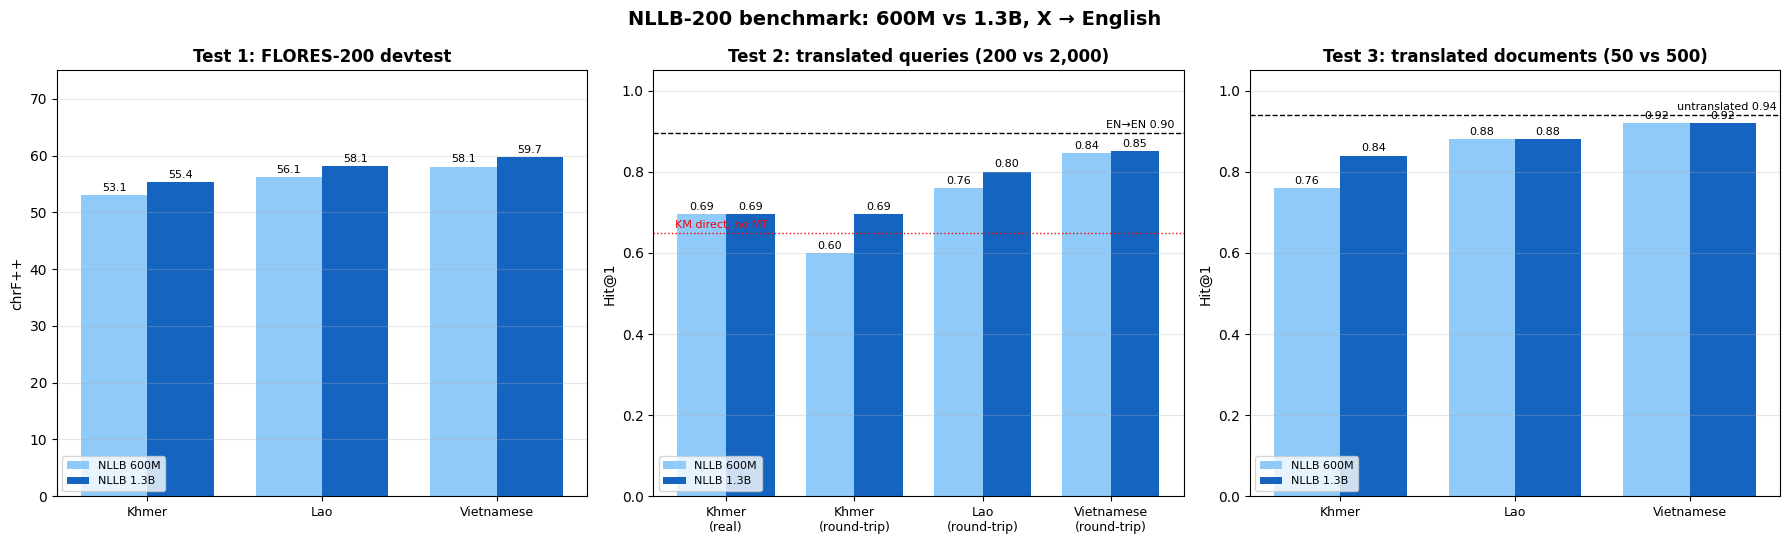

saved out/nllb_benchmark.png and out/nllb_benchmark_results.json


In [8]:
# Chart: 3 tests × 3 languages × 2 models
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle("NLLB-200 benchmark: 600M vs 1.3B, X → English", fontsize=14, fontweight="bold")
mcol = {"600M": "#90CAF9", "1.3B": "#1565C0"}
w = 0.38

def panel(ax, groups, getter, title, ylabel, ylim, baseline=None, base_label=None):
    x = np.arange(len(groups))
    for i, m in enumerate(NLLB_MODELS):
        vals = [getter(m, g) for g in groups]
        bars = ax.bar(x + (i - 0.5) * w, vals, w, label=f"NLLB {m}", color=mcol[m])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + ylim * 0.01, f"{v:.2f}" if ylim <= 1.5 else f"{v:.1f}",
                    ha="center", fontsize=8)
    if baseline is not None:
        ax.axhline(baseline, color="black", ls="--", lw=1)
        ax.text(len(groups) - 0.5, baseline + ylim * 0.012, base_label, ha="right", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(groups, fontsize=9)
    ax.set_ylim(0, ylim); ax.set_title(title, fontweight="bold"); ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3); ax.legend(fontsize=8, loc="lower left")

langs = [v[0] for v in LANGS.values()]
panel(axes[0], langs, lambda m, l: t1[(t1.model == m) & (t1.lang == l) & (t1.split == "devtest")]["chrF++"].item(),
      "Test 1: FLORES-200 devtest", "chrF++", 75)

g2 = ["Khmer\n(real)", "Khmer\n(round-trip)", "Lao\n(round-trip)", "Vietnamese\n(round-trip)"]
def get2(m, g):
    l = g.split("\n")[0]
    mode = "real Khmer → EN" if "real" in g else "round-trip EN→X→EN"
    return t2[(t2.model == m) & (t2.lang == l) & (t2["mode"] == mode)]["Hit@1"].item()
panel(axes[1], g2, get2, "Test 2: translated queries (200 vs 2,000)", "Hit@1", 1.05,
      b2["Hit@1"], f"EN→EN {b2['Hit@1']:.2f}")
axes[1].axhline(RESULTS["baselines"]["test2_KM->EN_direct_no_translation"]["Hit@1"], color="red", ls=":", lw=1)
axes[1].text(-0.4, RESULTS["baselines"]["test2_KM->EN_direct_no_translation"]["Hit@1"] + 0.012,
             "KM direct, no MT", fontsize=8, color="red")

panel(axes[2], langs, lambda m, l: t3[(t3.model == m) & (t3.lang == l)]["Hit@1"].item(),
      "Test 3: translated documents (50 vs 500)", "Hit@1", 1.05, b3["Hit@1"], f"untranslated {b3['Hit@1']:.2f}")

plt.tight_layout()
plt.savefig("out/nllb_benchmark.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("saved out/nllb_benchmark.png and", OUT_JSON)